In [ ]:
#!pip install opencv-contrib-python
from tensorflow import keras
import matplotlib.pyplot as plt
import tensorflow as tf
import pandas as pd
import numpy as np
import imageio
import cv2
import os

In [ ]:

DATA_FOLDER = 'dataset'
TRAIN_SAMPLE_FOLDER = 'train_sample_videos'
TEST_FOLDER ='test_videos'

print(f"train samples: {len(os.listdir(os.path.join(DATA_FOLDER, TRAIN_SAMPLE_FOLDER)))}")
print(f"test samples: {len(os.listdir(os.path.join(DATA_FOLDER, TEST_FOLDER)))}")

train samples: 249
test samples: 159


In [ ]:
train_sample_metadata = pd.read_json('dataset/train_sample_videos/metadata.json').T
train_sample_metadata.head()

,label,split,original
aagfhgtpmv.mp4,FAKE,train,vudstovrck.mp4
aapnvogymq.mp4,FAKE,train,jdubbvfswz.mp4
abarnvbtwb.mp4,REAL,train,None
abofeumbvv.mp4,FAKE,train,atvmxvwyns.mp4
abqwwspghj.mp4,FAKE,train,qzimuostzz.mp4


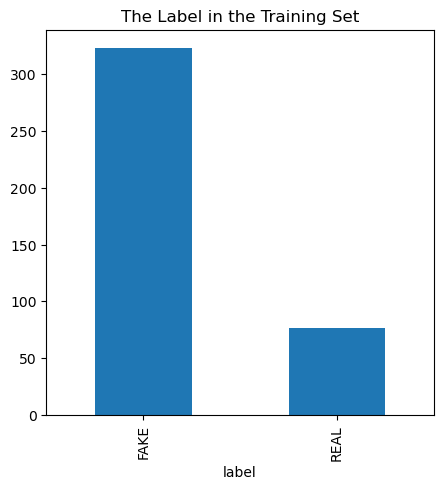

In [ ]:
train_sample_metadata.groupby('label')['label'].count().plot(figsize=(5,5),kind='bar',title='The Label in the Training Set')
plt.show()

In [ ]:

train_sample_metadata.shape

(400, 3)

In [ ]:
f_train_sample_video = list(train_sample_metadata.loc[train_sample_metadata.label=='FAKE'].sample(5).index)
f_train_sample_video

['cettndmvzl.mp4',
 'arlmiizoob.mp4',
 'bghphrsfxf.mp4',
 'avssvvsdhz.mp4',
 'apatcsqejh.mp4']

In [ ]:
def capture_image_from_video():
    capture_image = cv2.VideoCapture('dataset/train_sample_videos/btjwbtsgln.mp4')
    ret, frame = capture_image.read()
    fig = plt.figure(figsize =(10,10))
    ax = fig.add_subplot(111)
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    ax.imshow(frame)

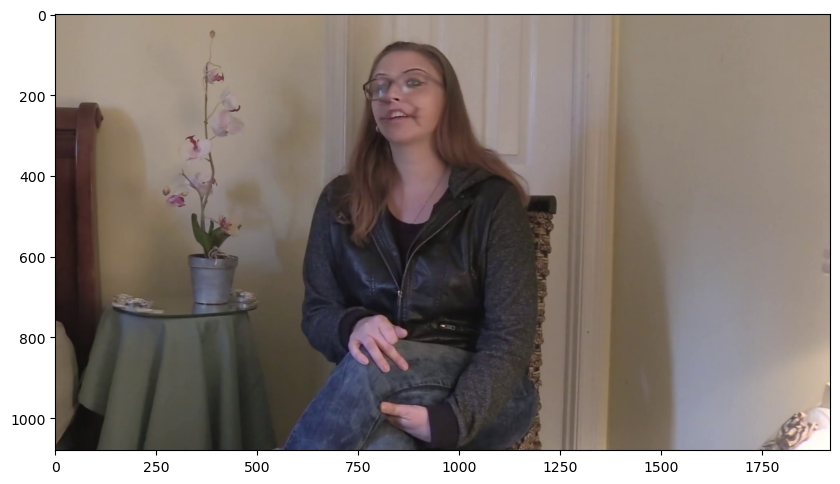

In [ ]:

capture_image_from_video()

In [ ]:
r_train_sample_video = list(train_sample_metadata.loc[train_sample_metadata.label=='REAL'].sample(1).index)
r_train_sample_video

['eudeqjhdfd.mp4']

In [ ]:
f_videos = list(train_sample_metadata.loc[train_sample_metadata.label=='FAKE'].index)

In [ ]:
from IPython.display import HTML
from base64 import b64encode

def capture_image_from_video():
    capture_image = cv2.VideoCapture('dataset/train_sample_videos/eudeqjhdfd.mp4')
    ret, frame = capture_image.read()
    fig = plt.figure(figsize =(10,10))
    ax = fig.add_subplot(111)
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    ax.imshow(frame)
    

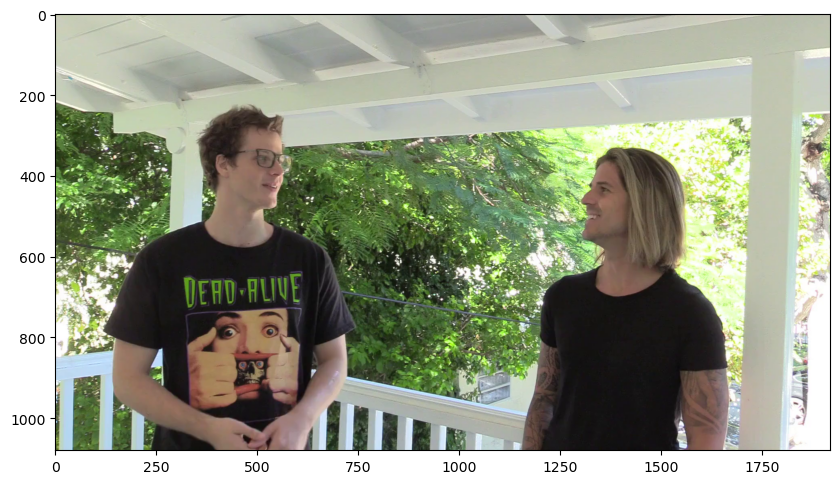

In [ ]:

capture_image_from_video()

**Modelling**

In [ ]:
img_size = 224
batch_size = 64
epochs = 70

max_seq_length = 20
num_features = 2048

In [ ]:
def crop_center_square(frame):
    y,x = frame.shape[0:2]
    min_dim = min(y, x)
    start_x = (x // 2) - (min_dim // 2)
    start_y = (y // 2) - (min_dim // 2)
    return frame[start_y :start_y + min_dim, start_x : start_x + min_dim]

def load_video(path, max_frames=0, resize=(img_size, img_size)):
    cap = cv2.VideoCapture(path)
    frames = []
    try:
        while 1:
            ret, frame = cap.read()
            if not ret:
                break
            frame = crop_center_square(frame)
            frame = cv2.resize(frame, resize)
            frame = frame[:, :, [2, 1, 0]]
            frames.append(frame)
            
            if len(frames) == max_frames:
                break
    finally:
        cap.release()
    return np.array(frames)
    

In [ ]:
def pretrain_feature_extractor():
    feature_extractor = keras.applications.InceptionV3(
    weights = "imagenet",
    include_top=False,
    pooling="avg",
    input_shape = (img_size,img_size,3)
    )
    preprocess_input = keras.applications.inception_v3.preprocess_input
    
    inputs = keras.Input((img_size,img_size,3))
    preprocessed = preprocess_input(inputs)
    
    outputs = feature_extractor(preprocessed)
    return keras.Model(inputs, outputs, name="feature_extractor")

feature_extractor = pretrain_feature_extractor()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 22s 0us/step


In [ ]:
def prepare_all_videos(df, root_dir): #df是train_sample_metadata->json的split
    num_samples = len(df)
    video_paths = list(df.index)
    labels = df["label"].values
    labels = np.array(labels=='FAKE').astype(int)
    
    frame_masks = np.zeros(shape=(num_samples, max_seq_length), dtype="bool")
    frame_features = np.zeros(
        shape=(num_samples, max_seq_length, num_features), dtype="float32"
    )
    
    for idx, path in enumerate(video_paths):
        frames = load_video(os.path.join(root_dir, path))
        frames = frames[None, ...]
        
        temp_frame_mask = np.zeros(shape=(1, max_seq_length,), dtype="bool")
        temp_frame_features = np.zeros(shape=(1, max_seq_length, num_features), dtype="float32")
        
        for i, batch in enumerate(frames):
            video_length = batch.shape[0]
            length = min(max_seq_length, video_length)
            for j in range(length):
                temp_frame_features[i, j, :] =feature_extractor.predict(batch[None, j, :])
            temp_frame_mask[i, :length] =1 # 1 = not masked, 0 = masked
        
        frame_features[idx,] =temp_frame_features.squeeze()
        frame_masks[idx,] =temp_frame_mask.squeeze()
    
    return (frame_features, frame_masks), labels

In [ ]:
from sklearn.model_selection import train_test_split

Train_set , Test_set = train_test_split(train_sample_metadata, test_size=0.1,random_state=42,
                                       stratify=train_sample_metadata['label'])
print(Train_set.shape, Test_set.shape)

(360, 3) (40, 3)


In [ ]:


train_data, train_labels = prepare_all_videos(Train_set, "train")
test_data, test_labels = prepare_all_videos(Test_set, "test")

print(f"Frame features in train set:{train_data[0].shape}")
print(f"Frame masks in train set:{train_data[1].shape}")

Frame features in train set:(360, 20, 2048)
Frame masks in train set:(360, 20)


# model 1_ GRU

In [ ]:
frame_features_input = keras.Input((max_seq_length, num_features))
mask_input = keras.Input((max_seq_length,),dtype="bool")

x = keras.layers.GRU(16, return_sequences=True)(frame_features_input, mask = mask_input)
x = keras.layers.GRU(8)(x)
x = keras.layers.Dropout(0.4)(x)
x = keras.layers.Dense(8, activation="relu")(x)
output = keras.layers.Dense(1, activation="sigmoid")(x)

model = keras.Model([frame_features_input, mask_input], output)
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)    │ (None, 20, 2048)          │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ input_layer_3 (InputLayer)    │ (None, 20)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ gru (GRU)                     │ (None, 20, 16)            │          99,168 │ input_layer_2[0][0],       │
│                               │                           │                 │ input_layer_3[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ gru_1 (GRU)                   │ (None, 8)                 │             624 │ gru[0][0],                 │
│                               │                           │                 │ input_layer_3[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 8)                 │               0 │ gru_1[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 8)                 │              72 │ dropout[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 1)                 │               9 │ dense[0][0]                │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 99,873 (390.13 KB)

 Trainable params: 99,873 (390.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
checkpoint = keras.callbacks.ModelCheckpoint('gru./.weights.h5', save_weights_only=True, save_best_only=True)
history = model.fit(
        [train_data[0], train_data[1]],
        train_labels,
        validation_data=([test_data[0], test_data[1]], test_labels),
        callbacks=[checkpoint],
        epochs=epochs,
        batch_size=8
)

Epoch 1/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.7972 - loss: 0.6868 - val_accuracy: 0.8000 - val_loss: 0.6806
Epoch 2/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8083 - loss: 0.6746 - val_accuracy: 0.8000 - val_loss: 0.6693
Epoch 3/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8083 - loss: 0.6634 - val_accuracy: 0.8000 - val_loss: 0.6580
Epoch 4/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8083 - loss: 0.6525 - val_accuracy: 0.8000 - val_loss: 0.6484
Epoch 5/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8083 - loss: 0.6424 - val_accuracy: 0.8000 - val_loss: 0.6389
Epoch 6/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8083 - loss: 0.6328 - val_accuracy: 0.8000 - val_loss: 0.6299
Epoch 7/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8083 - loss: 0.6236 - val_accuracy: 0.8000 - val_loss: 0.6216
Epoch 8/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8083 - loss: 0.6151 - val_accuracy: 0.8000 - v

Epoch 59/70
45/45 [==============================] - 1s 23ms/step - loss: 0.4909 - accuracy: 0.8083 - val_loss: 0.5014 - val_accuracy: 0.8000
Epoch 60/70
45/45 [==============================] - 1s 22ms/step - loss: 0.4907 - accuracy: 0.8083 - val_loss: 0.5013 - val_accuracy: 0.8000
Epoch 61/70
45/45 [==============================] - 1s 24ms/step - loss: 0.4906 - accuracy: 0.8083 - val_loss: 0.5012 - val_accuracy: 0.8000
Epoch 62/70
45/45 [==============================] - 1s 25ms/step - loss: 0.4904 - accuracy: 0.8083 - val_loss: 0.5011 - val_accuracy: 0.8000
Epoch 63/70
45/45 [==============================] - 1s 24ms/step - loss: 0.4902 - accuracy: 0.8083 - val_loss: 0.5010 - val_accuracy: 0.8000
Epoch 64/70
45/45 [==============================] - 1s 27ms/step - loss: 0.4901 - accuracy: 0.8083 - val_loss: 0.5009 - val_accuracy: 0.8000
Epoch 65/70
45/45 [==============================] - 1s 24ms/step - loss: 0.4900 - accuracy: 0.8083 - val_loss: 0.5009 - val_accuracy: 0.8000
Epoch 

In [ ]:
test_videos = pd.DataFrame(list(os.listdir(os.path.join(DATA_FOLDER, TEST_FOLDER))), columns=['video'])

In [ ]:
def prepare_single_video(frames):
    frames = frames[None, ...]
    frame_mask = np.zeros(shape=(1, max_seq_length,), dtype="bool")
    frame_features = np.zeros(shape=(1, max_seq_length, num_features), dtype="float32")

    for i, batch in enumerate(frames):
        video_length = batch.shape[0]
        length = min(max_seq_length, video_length)
        for j in range(length):
            frame_features[i, j, :] = feature_extractor.predict(batch[None, j, :])
        frame_mask[i, :length] = 1  # 1 = not masked, 0 = masked

    return frame_features, frame_mask

def sequence_prediction(path):
    frames = load_video(os.path.join(DATA_FOLDER, TEST_FOLDER,path))
    frame_features, frame_mask = prepare_single_video(frames)
    return model.predict([frame_features, frame_mask])[0]
    

def to_gif(images):
    converted_images = images.astype(np.uint8)
    imageio.mimsave("animation.gif", converted_images, fps=10)
    return embed.embed_file("animation.gif")


test_video = np.random.choice(test_videos["video"].values.tolist())
print(f"Test video path: {test_video}")

if(sequence_prediction(test_video)>=0.5):
    print(f'The predicted class of the video is FAKE')
else:
    print(f'The predicted class of the video is REAL')

play_video(test_video,TEST_FOLDER)

Test video path: dvwpvqdflx.mp4
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
The predicted class of the video is FAKE


In [ ]:
def prepare_single_video(frames):
    frames = frames[None, ...]
    frame_mask = np.zeros(shape=(1, max_seq_length,), dtype="bool")
    frame_features = np.zeros(shape=(1, max_seq_length, num_features), dtype="float32")

    for i, batch in enumerate(frames):
        video_length = batch.shape[0]
        length = min(max_seq_length, video_length)
        for j in range(length):
            frame_features[i, j, :] = feature_extractor.predict(batch[None, j, :])
        frame_mask[i, :length] = 1  # 1 = not masked, 0 = masked

    return frame_features, frame_mask

def sequence_prediction(path):
    frames = load_video(os.path.join(DATA_FOLDER, TEST_FOLDER,path))
    frame_features, frame_mask = prepare_single_video(frames)
    return model.predict([frame_features, frame_mask])[0]
    

def to_gif(images):
    converted_images = images.astype(np.uint8)
    imageio.mimsave("animation.gif", converted_images, fps=10)
    return embed.embed_file("animation.gif")


test_video = 'bwbp1.mp4'
print(f"Test video path: {test_video}")

if(sequence_prediction(test_video)>=0.5):
    print(f'The predicted class of the video is REAL')
else:
    print(f'The predicted class of the video is FAKE')

play_video(test_video,TEST_FOLDER)

Test video path: bwbp1.mp4
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
The predicted class of the video is REAL


# MODEL2_LSTM

In [ ]:
from tensorflow import keras


frame_features_input = keras.Input((max_seq_length, num_features))
mask_input = keras.Input((max_seq_length,), dtype="bool")


x = keras.layers.LSTM(32, return_sequences=True)(frame_features_input, mask=mask_input)

x = keras.layers.LSTM(16)(x)


x = keras.layers.Dropout(0.4)(x)
x = keras.layers.Dense(8, activation="relu")(x)


output = keras.layers.Dense(1, activation="sigmoid")(x)


model_lstm = keras.Model([frame_features_input, mask_input], output)


model_lstm.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)


model_lstm.summary()


checkpoint = keras.callbacks.ModelCheckpoint(
    'lstm./.weights.h5',
    save_weights_only=True,
    save_best_only=True,
    monitor="val_accuracy",
    mode="max",
    verbose=1
)


history_lstm = model_lstm.fit(
    [train_data[0], train_data[1]],    # frame_features, mask
    train_labels,
    validation_data=([test_data[0], test_data[1]], test_labels),
    callbacks=[checkpoint],
    epochs=epochs,
    batch_size=8
)



Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)    │ (None, 20, 2048)          │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ input_layer_7 (InputLayer)    │ (None, 20)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm_2 (LSTM)                 │ (None, 20, 32)            │         266,368 │ input_layer_6[0][0],       │
│                               │                           │                 │ input_layer_7[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm_3 (LSTM)                 │ (None, 16)                │           3,136 │ lstm_2[0][0],              │
│                               │                           │                 │ input_layer_7[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_2 (Dropout)           │ (None, 16)                │               0 │ lstm_3[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_4 (Dense)               │ (None, 8)                 │             136 │ dropout_2[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_5 (Dense)               │ (None, 1)                 │               9 │ dense_4[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 269,649 (1.03 MB)

 Trainable params: 269,649 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6835 - loss: 0.6904    
Epoch 1: val_accuracy improved from None to 0.80000, saving model to ./.weights.h5
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.7861 - loss: 0.6868 - val_accuracy: 0.8000 - val_loss: 0.6812
Epoch 2/70
44/45 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7863 - loss: 0.6788
Epoch 2: val_accuracy did not improve from 0.80000
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8083 - loss: 0.6746 - val_accuracy: 0.8000 - val_loss: 0.6695
Epoch 3/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7843 - loss: 0.6680
Epoch 3: val_accuracy did not improve from 0.80000
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8083 - loss: 0.6630 - val_accuracy: 0.8000 - val_loss: 0.6583
Epoch 4/70
42/45 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8410 - loss: 0.6506
Epoch 4: val_accuracy did not improve from 0.80000
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8083 - loss: 0.652

# MODEL3_CNN MODEL

In [ ]:
from tensorflow import keras


frame_features_input = keras.Input((max_seq_length, num_features))


x = keras.layers.Masking()(frame_features_input)
x = keras.layers.Conv1D(64, 3, activation="relu", padding="same")(x)
x = keras.layers.MaxPooling1D(pool_size=2)(x)
x = keras.layers.Conv1D(32, 3, activation="relu", padding="same")(x)
x = keras.layers.GlobalAveragePooling1D()(x)


x = keras.layers.Dropout(0.4)(x)
x = keras.layers.Dense(16, activation="relu")(x)
output = keras.layers.Dense(1, activation="sigmoid")(x)

model_cnn = keras.Model(frame_features_input, output)
model_cnn.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model_cnn.summary()


checkpoint = keras.callbacks.ModelCheckpoint('cnn./.weights.h5', save_weights_only=True, save_best_only=True)


history_cnn = model_cnn.fit(
    train_data[0],           # only frame features
    train_labels,
    validation_data=(test_data[0], test_labels),
    callbacks=[checkpoint],
    epochs=epochs,
    batch_size=8
)


C:\Users\alex\anaconda3\Lib\site-packages\keras\src\layers\layer.py:970: UserWarning: Layer 'conv1d_2' (of type Conv1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)          │ (None, 20, 2048)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ masking_1 (Masking)                  │ (None, 20, 2048)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 20, 64)              │         393,280 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 10, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_3 (Conv1D)                    │ (None, 10, 32)              │           6,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d_1           │ (None, 32)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 400,001 (1.53 MB)

 Trainable params: 400,001 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8028 - loss: 0.6866 - val_accuracy: 0.8000 - val_loss: 0.6805
Epoch 2/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8083 - loss: 0.6743 - val_accuracy: 0.8000 - val_loss: 0.6692
Epoch 3/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8083 - loss: 0.6628 - val_accuracy: 0.8000 - val_loss: 0.6582
Epoch 4/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8083 - loss: 0.6519 - val_accuracy: 0.8000 - val_loss: 0.6476
Epoch 5/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8083 - loss: 0.6415 - val_accuracy: 0.8000 - val_loss: 0.6382
Epoch 6/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8083 - loss: 0.6320 - val_accuracy: 0.8000 - val_loss: 0.6287
Epoch 7/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8083 - loss: 0.6227 - val_accuracy: 0.8000 - val_loss: 0.6208
Epoch 8/70
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8083 - loss: 0.6142 - val_accuracy: 0.8000 - v